# 03 · Modelado

Objetivo: elegir el tipo de modelo y construir el pipeline completo **usando solo train (ajuste) y validación (selección)**.
El test interno y el holdout externo no se tocan aquí; se usan una sola vez en el notebook 05.

Pipeline final (el desplegado en la API):

1. **Gradient Boosting de stumps** (150 árboles de profundidad 1, `learning_rate` 0,04) con pesos balanceados — ajustado en train.
2. **Calibración Platt** sobre el logit — ajustada en validación.
3. **Umbral de revisión**: máximo F1 en validación con FPR ≤ 5 %.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data_processing import FEATURE_NAMES, get_split, load_dataset, split_xy
from src.evaluate import classification_metrics, full_report, ppv_at_prevalence, wilson_interval
from src.model import load_model, predict_proba, threshold
from src.train import DEPLOYED_PARAMS, SEED, BalancedGradientBoosting, build_baseline, fit_platt, select_threshold

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
MET = ROOT / "results" / "metrics"
dev = load_dataset(ROOT / "data/processed/development_dataset_v6.csv")
ext = load_dataset(ROOT / "data/processed/external_holdout_v6.csv")
X_train, y_train, g_train = split_xy(get_split(dev, "train"))
X_val, y_val, g_val = split_xy(get_split(dev, "validation"))
FIG = ROOT / "results" / "figures" / "modelado"
FIG.mkdir(parents=True, exist_ok=True)
print(f"Train {len(y_train)} ({y_train.sum()} riesgosas) · validación {len(y_val)} ({y_val.sum()} riesgosas)")

2026-10-29 04:09:09,927 INFO src.data_processing: Dataset development_dataset_v6.csv: 1854 filas, 44 columnas


2026-10-29 04:09:09,939 INFO src.data_processing: Dataset external_holdout_v6.csv: 286 filas, 44 columnas


Train 1294 (280 riesgosas) · validación 278 (60 riesgosas)


## 1. Candidatos y baselines

| Modelo | Por qué se prueba |
|---|---|
| Dummy estratificado | Piso de azar con la misma prevalencia (PR-AUC ≈ prevalencia) |
| Regresión logística (log1p + escalado) | Baseline lineal interpretable |
| Árbol de decisión (prof. 4) | Reglas simples legibles |
| Random Forest (balanceado) | Ensamble no lineal fuerte, sin restricción de exportación |
| **GB stumps (desplegado)** | Ensamble aditivo: cada árbol usa una sola variable, se exporta a JSON y se explica exactamente |
| GB profundidad 3 | Permite interacciones; no exportable al scorer actual |

Se comparan con **validación cruzada agrupada (GroupKFold por `matchedCaseId`, 5 pliegues) en train** y luego en validación.

In [2]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier

candidatos = {
    "Dummy estratificado": DummyClassifier(strategy="stratified", random_state=SEED),
    "Regresión logística": build_baseline(),
    "Árbol de decisión (prof. 4)": DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, class_weight="balanced",
                                                          random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=SEED),
    "GB stumps (desplegado)": BalancedGradientBoosting(**DEPLOYED_PARAMS),
    "GB profundidad 3": BalancedGradientBoosting(**{**DEPLOYED_PARAMS, "max_depth": 3}),
}
cv = GroupKFold(n_splits=5)
filas = []
for nombre, modelo in candidatos.items():
    cv_scores = cross_val_score(modelo, X_train, y_train, groups=g_train, cv=cv, scoring="average_precision")
    modelo.fit(X_train, y_train)
    p_val = modelo.predict_proba(X_val)[:, 1]
    elegido = select_threshold(p_val, y_val, 0.05) if nombre != "Dummy estratificado" else {"threshold": 0.5}
    m = classification_metrics(y_val, p_val, elegido["threshold"])
    filas.append({"modelo": nombre, "PR-AUC CV (train)": cv_scores.mean(), "± CV": cv_scores.std(),
                  "PR-AUC val": m["auc_pr"], "ROC-AUC val": m["auc"], "recall val": m["recall"],
                  "FPR val": m["fpr"], "F1 val": m["f1"]})
comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion.to_csv(MET / "modelado_comparacion_validacion.csv")
print(f"PR-AUC nulo (prevalencia de validación): {y_val.mean():.3f}")
comparacion.round(3)

PR-AUC nulo (prevalencia de validación): 0.216


,PR-AUC CV (train),± CV,PR-AUC val,ROC-AUC val,recall val,FPR val,F1 val
modelo,,,,,,,
Dummy estratificado,0.220,0.010,0.210,0.480,0.167,0.206,0.174
Regresión logística,0.881,0.025,0.888,0.969,0.717,0.037,0.775
Árbol de decisión (prof. 4),0.848,0.031,0.826,0.964,0.750,0.032,0.804
Random Forest,0.913,0.016,0.929,0.983,0.917,0.037,0.894
GB stumps (desplegado),0.910,0.011,0.935,0.981,0.917,0.041,0.887
GB profundidad 3,0.918,0.018,0.949,0.986,0.900,0.032,0.893


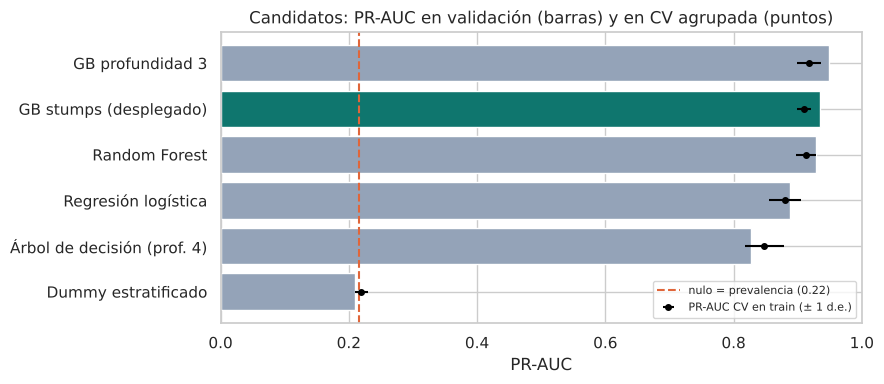

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
orden = comparacion.sort_values("PR-AUC val")
colores = ["#0f766e" if "desplegado" in n else "#94a3b8" for n in orden.index]
ax.barh(orden.index, orden["PR-AUC val"], color=colores)
ax.errorbar(orden["PR-AUC CV (train)"], orden.index, xerr=orden["± CV"], fmt="o", color="black", ms=4,
            label="PR-AUC CV en train (± 1 d.e.)")
ax.axvline(y_val.mean(), ls="--", color="#e0663a", label=f"nulo = prevalencia ({y_val.mean():.2f})")
ax.set_xlim(0, 1)
ax.set_xlabel("PR-AUC")
ax.set_title("Candidatos: PR-AUC en validación (barras) y en CV agrupada (puntos)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "mod_01_comparacion_candidatos.png", dpi=160, bbox_inches="tight")
plt.show()

### Justificación del modelo elegido

Todos los modelos reales superan con amplitud al azar (PR-AUC nulo ≈ 0,22). Los tres ensambles (GB stumps, GB profundidad 3
y Random Forest) forman un grupo con PR-AUC de validación entre 0,93 y 0,95 y recall ≈ 0,90–0,92 con FPR ≈ 3–4 %: sus
diferencias son del mismo orden que la variación entre pliegues (± 0,01–0,02) y, con 60 positivos en validación, no son
concluyentes. La regresión logística y el árbol simple quedan claramente por debajo en recall con el mismo FPR.
Dentro del grupo de mejor rendimiento se elige **GB stumps** porque:

* cada árbol usa una sola variable → el modelo es **aditivo** y la contribución de cada variable es exacta (se muestra en la interfaz);
* se **exporta a JSON** y lo ejecuta el scorer TypeScript de la API sin dependencias de Python;
* tiene menos capacidad de memorizar ruido que árboles profundos con ~1 300 filas.

## 2. Diagnóstico de sobreajuste: número de árboles

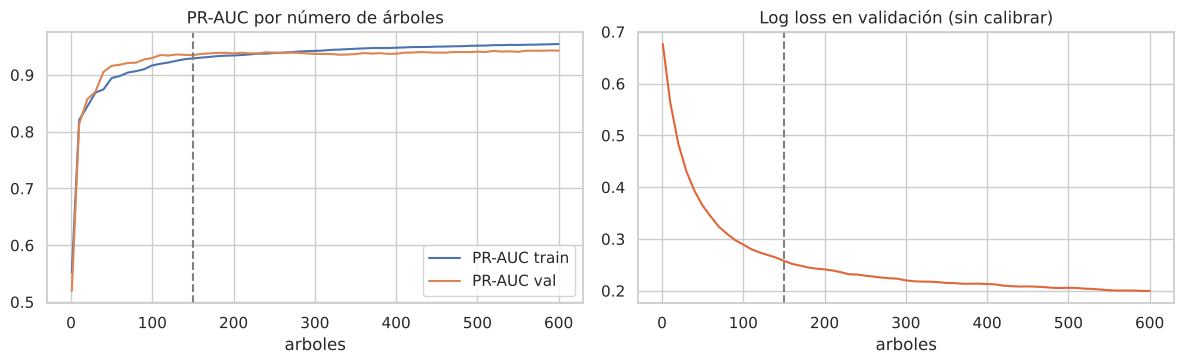

,PR-AUC train,PR-AUC val,log loss val
arboles,,,
10,0.821,0.813,0.565
50,0.894,0.916,0.364
150,0.929,0.935,0.258
300,0.942,0.937,0.220
600,0.954,0.943,0.200


In [4]:
from sklearn.metrics import average_precision_score, log_loss

gb_largo = BalancedGradientBoosting(**{**DEPLOYED_PARAMS, "n_estimators": 600}).fit(X_train, y_train)
etapas = []
for n, (raw_tr, raw_va) in enumerate(zip(gb_largo.model_.staged_decision_function(X_train),
                                         gb_largo.model_.staged_decision_function(X_val)), start=1):
    if n % 10 == 0 or n == 1:
        etapas.append({"arboles": n, "PR-AUC train": average_precision_score(y_train, raw_tr),
                       "PR-AUC val": average_precision_score(y_val, raw_va),
                       "log loss val": log_loss(y_val, 1 / (1 + np.exp(-raw_va.ravel())))})
etapas = pd.DataFrame(etapas).set_index("arboles")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
etapas[["PR-AUC train", "PR-AUC val"]].plot(ax=ax[0])
ax[0].axvline(150, ls="--", color="gray")
ax[0].set_title("PR-AUC por número de árboles")
etapas["log loss val"].plot(ax=ax[1], color="#e0663a")
ax[1].axvline(150, ls="--", color="gray")
ax[1].set_title("Log loss en validación (sin calibrar)")
plt.tight_layout()
plt.savefig(FIG / "mod_02_curva_arboles.png", dpi=160, bbox_inches="tight")
plt.show()
etapas.loc[[10, 50, 150, 300, 600]].round(3)

**Lectura.** La brecha train–validación es pequeña: los stumps no sobreajustan con fuerza. El log loss de validación
sigue bajando después de 150 árboles, así que 150 **no es el punto de convergencia**; el diagnóstico de octubre
(`results/reports/overfitting-v7/`) confirmó que ninguna alternativa gana con significancia estadística y por eso la
configuración desplegada se mantiene. El próximo ciclo usa *early stopping* con paciencia 50 (`docs/TRAINING_GOVERNANCE.md`).

## 3. Calibración Platt (en validación)

Platt: p = sigmoid(1.8490 · logit + (-1.9443))


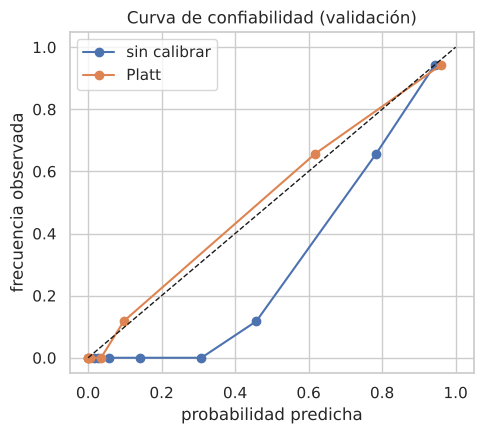

In [5]:
gb = BalancedGradientBoosting(**DEPLOYED_PARAMS).fit(X_train, y_train)
raw_val = gb.model_.decision_function(X_val)
a, b = fit_platt(raw_val, y_val)
p_val = 1 / (1 + np.exp(-(a * raw_val + b)))
print(f"Platt: p = sigmoid({a:.4f} · logit + ({b:.4f}))")

from sklearn.calibration import calibration_curve
fig, ax = plt.subplots(figsize=(5, 4.5))
for nombre, prob in [("sin calibrar", 1 / (1 + np.exp(-raw_val))), ("Platt", p_val)]:
    frac, media = calibration_curve(y_val, prob, n_bins=8, strategy="quantile")
    ax.plot(media, frac, "o-", label=nombre)
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("probabilidad predicha")
ax.set_ylabel("frecuencia observada")
ax.set_title("Curva de confiabilidad (validación)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "mod_03_calibracion.png", dpi=160, bbox_inches="tight")
plt.show()

La calibración corrige la escala de las probabilidades **dentro de la muestra caso-control** (≈ 22 % de riesgosas).
No convierte la salida en una probabilidad de producción: con una prevalencia real cercana al 1 % el mismo puntaje
corresponde a un riesgo mucho menor. Por eso la API la llama *probabilidad muestral*.

## 4. Umbral de revisión

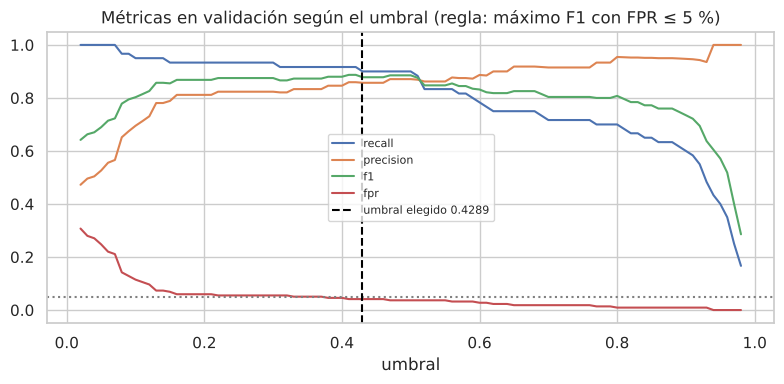

threshold    0.4289
accuracy     0.9496
recall       0.9167
precision    0.8594
f1           0.8871
fpr          0.0413
auc          0.9814
auc_pr       0.9350
dtype: float64

In [6]:
umbrales = np.linspace(0.02, 0.98, 97)
curva = pd.DataFrame([{"umbral": t, **classification_metrics(y_val, p_val, t)} for t in umbrales]).set_index("umbral")
elegido = select_threshold(p_val, y_val, max_fpr=0.05)
fig, ax = plt.subplots(figsize=(8, 4))
curva[["recall", "precision", "f1", "fpr"]].plot(ax=ax)
ax.axhline(0.05, ls=":", color="gray")
ax.axvline(elegido["threshold"], ls="--", color="black", label=f"umbral elegido {elegido['threshold']:.4f}")
ax.set_title("Métricas en validación según el umbral (regla: máximo F1 con FPR ≤ 5 %)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG / "mod_04_umbral.png", dpi=160, bbox_inches="tight")
plt.show()
pd.Series(elegido).round(4)

## 5. Reproducción exacta del artefacto desplegado

In [7]:
desplegado = load_model(ROOT / "models/model_v0.6.1.json")
diferencia = np.max(np.abs(p_val - predict_proba(desplegado, X_val)))
print(f"Máxima diferencia de probabilidad vs. JSON desplegado: {diferencia:.2e}")
print(f"Umbral reproducido: {elegido['threshold']!r} · desplegado: {threshold(desplegado)!r}")
assert diferencia < 1e-12 and abs(elegido["threshold"] - threshold(desplegado)) < 1e-12

Máxima diferencia de probabilidad vs. JSON desplegado: 2.22e-16
Umbral reproducido: 0.42888289739994356 · desplegado: 0.4288828973999436


El pipeline de `src/train.py` reproduce el modelo en producción **bit a bit** (diferencia < 10⁻¹²): mismo dataset,
misma semilla, mismos pasos. `python -m src.train` guarda este modelo en `models/best_model.pkl` y el baseline logístico en
`models/model_v1.pkl`.

**Siguiente paso:** la optimización de hiperparámetros y el análisis de sensibilidad están en `04_optimizacion.ipynb`;
la evaluación final en `05_evaluacion.ipynb`.